# Price Spikes

## Research question
Which physical conditions accompany positive and negative price extremes?

## Data
Source: Bundesnetzagentur | SMARD.de. Observed period: January 2023-18 November 2026; 63,843 native price intervals and 136,128 quarter-hours per core load/wind/solar series. Physical quantities are German net grid/load generation; prices cover DE-LU. Actuals and forecasts remain separate; no missing physical value is replaced by zero.

## Methodology and equations
Events are P<0 and P>=200 EUR/MWh. Consecutive periods must be physically contiguous. Trailing event quantiles use past observations; full-sample physical bins are descriptive rather than prospective thresholds.

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import Image, display
root = Path.cwd() if Path('reports').exists() else Path.cwd().parent
os.chdir(root)


In [2]:
from power_risk.spikes.events import negative_runs
from power_risk.fundamentals.research import dataset, bins
display(negative_runs(pd.read_parquet('data/processed/prices.parquet')).sort_values('duration_hours',ascending=False).head(8))
display(bins(dataset(), 'actual_load_mw', 'spike'))
display(pd.read_csv('reports/consecutive_positive_spikes.csv').head())

,start,end,duration_hours,minimum_price,intervals
44,2023-12-24 00:00:00+00:00,2023-12-25 12:00:00+00:00,36.00,-13.37,36
241,2025-10-04 19:30:00+00:00,2025-10-05 15:30:00+00:00,20.00,-5.09,80
96,2024-07-06 22:00:00+00:00,2024-07-07 16:00:00+00:00,18.00,-22.37,18
278,2026-04-04 23:30:00+00:00,2026-04-05 16:30:00+00:00,17.00,-114.53,68
238,2025-10-03 23:15:00+00:00,2025-10-04 15:30:00+00:00,16.25,-5.02,65
116,2024-08-24 23:00:00+00:00,2024-08-25 15:00:00+00:00,16.00,-20.01,16
133,2024-10-12 23:00:00+00:00,2024-10-13 15:00:00+00:00,16.00,-15.69,16
18,2023-07-02 02:00:00+00:00,2023-07-02 17:00:00+00:00,15.00,-500.00,15


,n,x,mean,median,std
bin,,,,,
"(30902.749, 44127.212]",6807,40591.098165,0.003673,0.0,0.060496
"(44127.212, 49666.408]",6806,46776.774392,0.015428,0.0,0.123255
"(49666.408, 55865.908]",6806,52872.353751,0.043344,0.0,0.203646
"(55865.908, 61022.75]",6807,58360.959127,0.047157,0.0,0.211991
"(61022.75, 78241.19]",6806,65888.842286,0.081693,0.0,0.273916


,start,end,hours,max_price
0,2023-01-20 06:00:00+00:00,2023-01-20 11:00:00+00:00,5.0,235.06
1,2023-01-20 15:00:00+00:00,2023-01-20 18:00:00+00:00,3.0,208.40
2,2023-01-22 17:00:00+00:00,2023-01-22 18:00:00+00:00,1.0,202.07
3,2023-01-23 06:00:00+00:00,2023-01-23 20:00:00+00:00,14.0,270.22
4,2023-01-24 06:00:00+00:00,2023-01-24 20:00:00+00:00,14.0,256.43


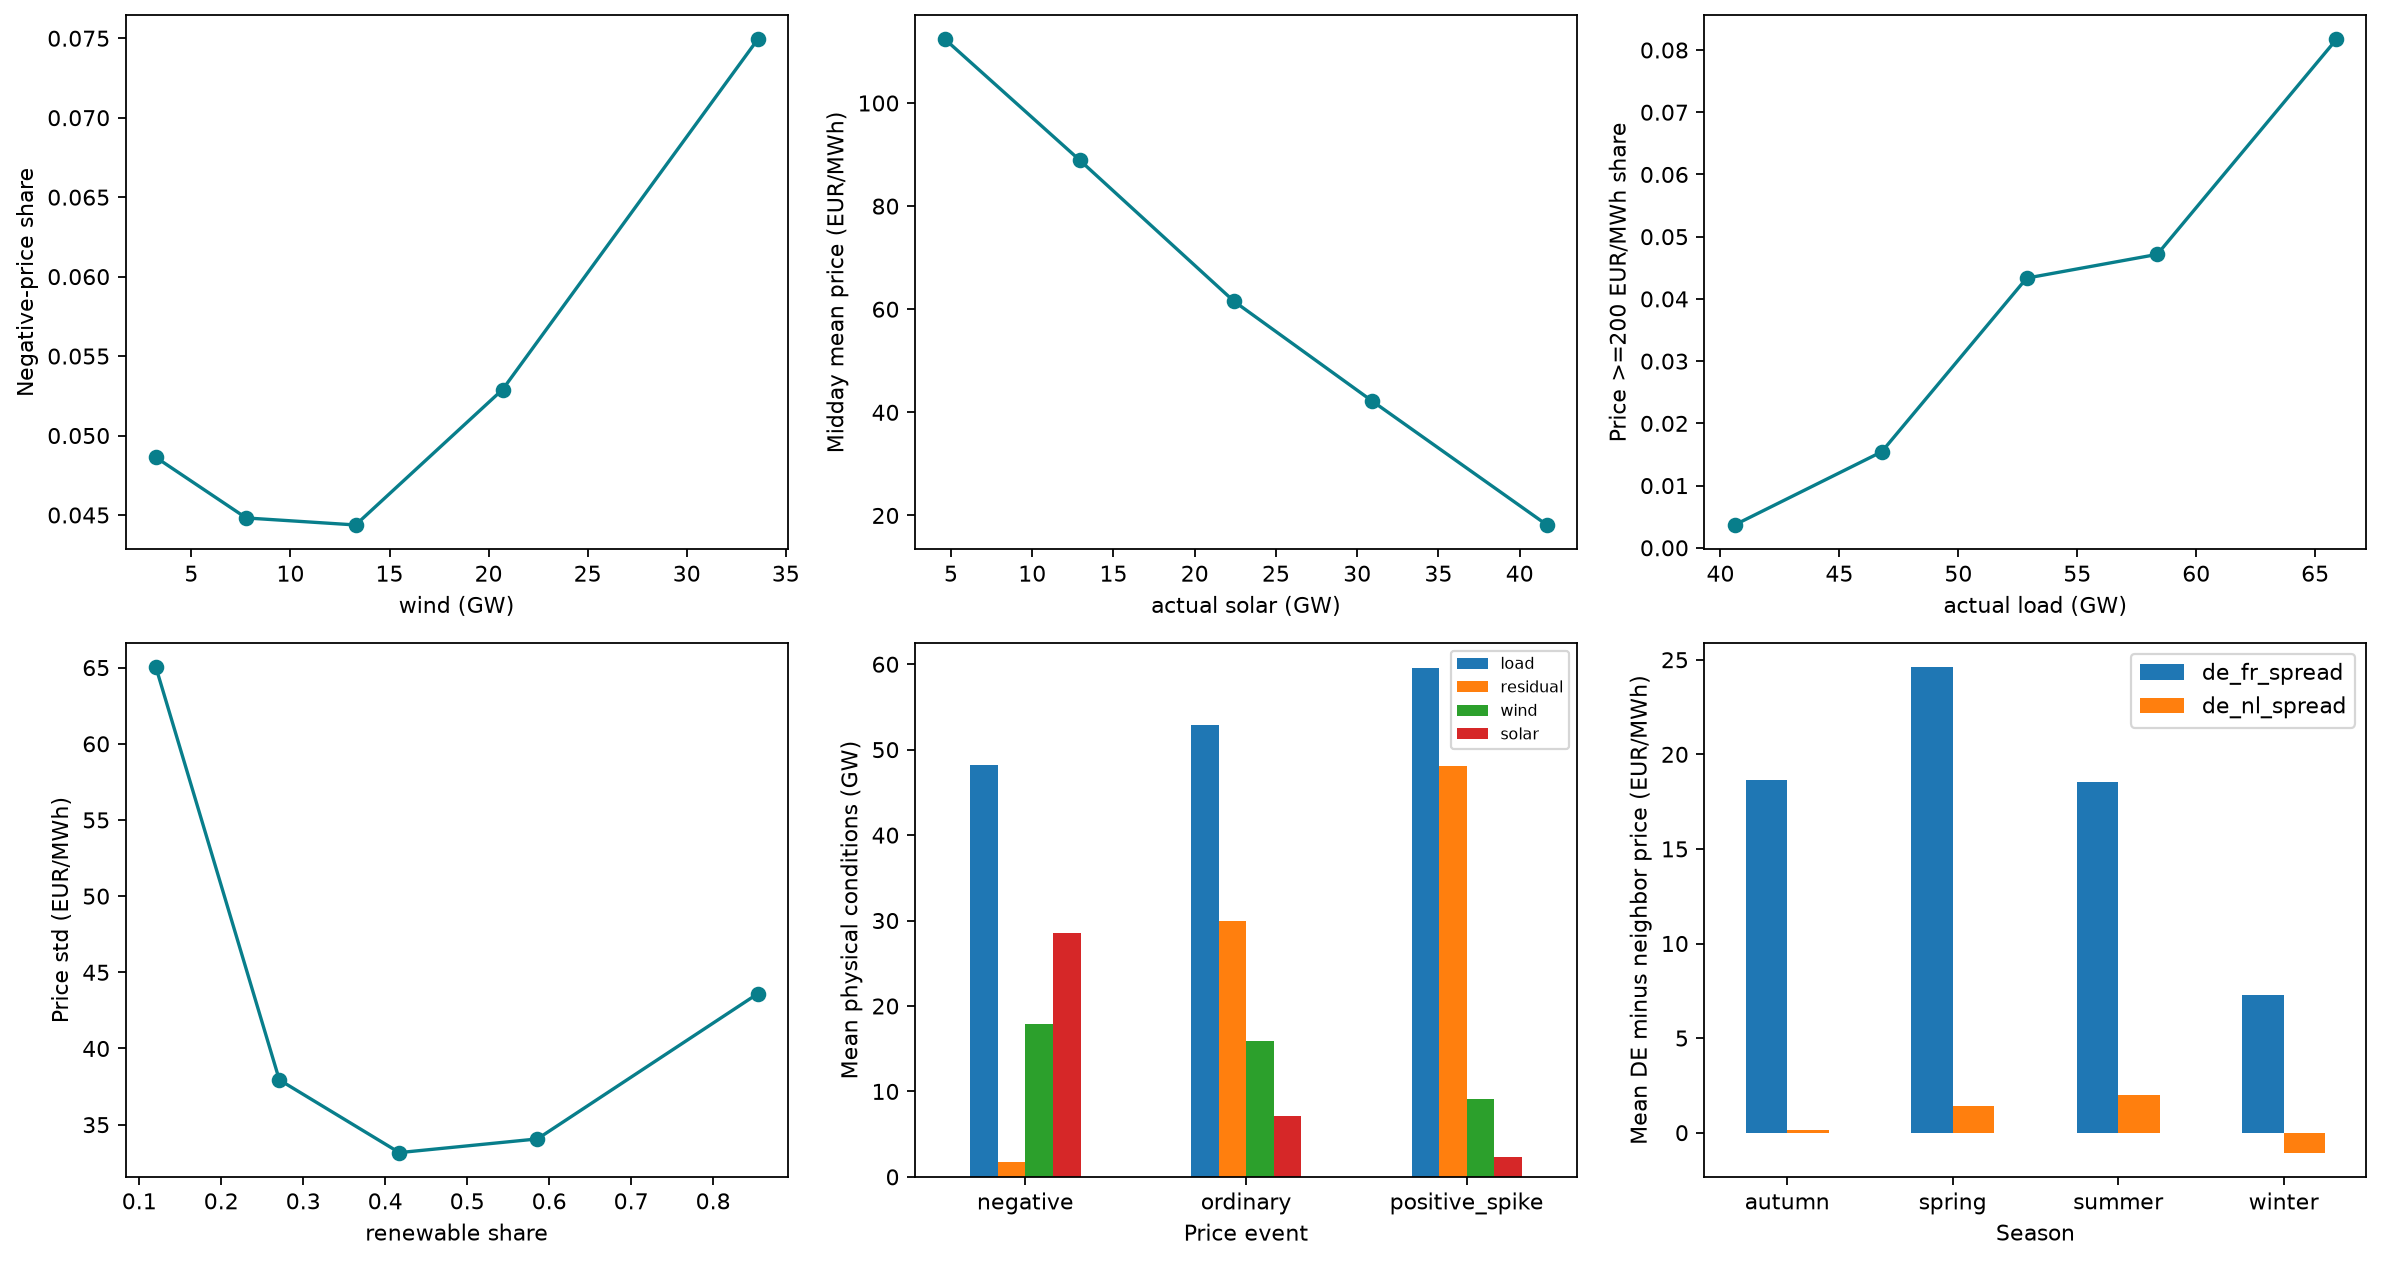

In [3]:
display(Image(filename='reports/renewable_price_analysis.png'))

## Quantitative findings and commercial interpretation
High-demand quartile spike incidence is 7.48%, versus 0.42% for low demand. High-wind negative-price incidence is 7.20% versus 4.67%. Low residual demand and inflexibility are plausible mechanisms, not identified causal explanations.

## Limitations
Thresholds are fixed research choices. Weather, demand, fuels, outages and cross-border conditions confound comparisons. No paid fuel proxy is silently substituted.

Calculations call reusable modules; regenerate underlying outputs using the README workflow.